# Loading Data

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import string


In [5]:
## Load the CSV file into a DataFrame
data = pd.read_csv('final_dataset.csv')
data


,title,text,subject,date,type
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,31-Dec-17,1
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,29-Dec-17,1
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,31-Dec-17,1
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,30-Dec-17,1
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,29-Dec-17,1
...,...,...,...,...,...
44914,McPain: John McCain Furious That Iran Treated ...,21st Century Wire says As 21WIRE reported earl...,Middle-east,16-Jan-16,0
44915,JUSTICE? Yahoo Settles E-mail Privacy Class-ac...,21st Century Wire says It s a familiar theme. ...,Middle-east,16-Jan-16,0
44916,Sunnistan: US and Allied ‘Safe Zone’ Plan to T...,Patrick Henningsen 21st Century WireRemember ...,Middle-east,15-Jan-16,0
44917,How to Blow $700 Million: Al Jazeera America F...,21st Century Wire says Al Jazeera America will...,Middle-east,14-Jan-16,0


### Adding libraries needed

# Data Exploration

#### data description 

In [6]:
data.describe()

,type
count,44919.000000
mean,0.476792
std,0.499467
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


### Features of columns in dataset 
    >TITLE- TITLE OF NEWS 
	>TEXT- DESCRIPTION OF THE NEWS
	>SUBJECT- Shows Type of News 
	>DATA - Shows date of news 
	>TYPE- shows news is true or false news(1(true) and 0(false))

In [7]:
data.columns

Index(['title', 'text', 'subject', 'date', 'type'], dtype='object')

#### Knowing datatypes of each column

In [8]:
data.dtypes

title      object
text       object
subject    object
date       object
type        int64
dtype: object

#### Histogram plotted based on type of data 

array([[<Axes: title={'center': 'type'}>]], dtype=object)

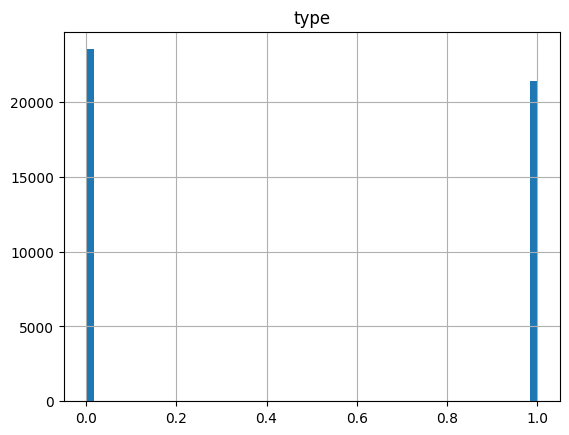

In [9]:
data.hist(bins=60)

In [10]:
data['type'].unique()

array([1, 0], dtype=int64)

#### Comparing true news and fake news via bar graph 

<Axes: xlabel='type'>

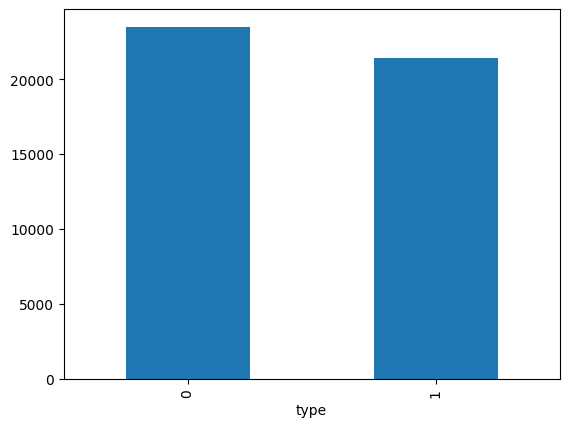

In [11]:
data['type'].value_counts().plot(kind='bar')

### Checking values for each columns 

In [12]:
data['type'].value_counts()

type
0    23502
1    21417
Name: count, dtype: int64

In [13]:
data['text'].value_counts().sum()

44919

In [14]:
data['title'].value_counts()

title
Factbox: Trump fills top jobs for his administration                                                     14
Factbox: Contenders for senior jobs in Trump's administration                                             8
Highlights: The Trump presidency on April 13 at 9:30 P.M. EDT/0130 GMT on Friday                          8
Factbox: International reaction to arrest of Reuters reporters in Myanmar                                 6
MEDIA IGNORES Time That Bill Clinton FIRED His FBI Director On Day Before Vince Foster Was Found Dead     6
                                                                                                         ..
Pope heads for Bangladesh after diplomatic balancing act in Myanmar                                       1
Japan emperor to cede all public duties after abdication: prince                                          1
Russia's Lavrov: little difference between policies of Trump and Obama - RIA                              1
Election crisis engulf

# Data cleaning

### Checking colums and Removing unnecessary columns 

In [15]:
data.columns

Index(['title', 'text', 'subject', 'date', 'type'], dtype='object')

In [16]:



#removal of unnecessary data 
df=data[['text','type']]
df

,text,type
0,WASHINGTON (Reuters) - The head of a conservat...,1
1,WASHINGTON (Reuters) - Transgender people will...,1
2,WASHINGTON (Reuters) - The special counsel inv...,1
3,WASHINGTON (Reuters) - Trump campaign adviser ...,1
4,SEATTLE/WASHINGTON (Reuters) - President Donal...,1
...,...,...
44914,21st Century Wire says As 21WIRE reported earl...,0
44915,21st Century Wire says It s a familiar theme. ...,0
44916,Patrick Henningsen 21st Century WireRemember ...,0
44917,21st Century Wire says Al Jazeera America will...,0


### checking for nulls and duplicate values

In [17]:
df.isna().sum()

text    0
type    0
dtype: int64

In [18]:
#checking for duplicates 
df['text'].duplicated().sum()


6262

#### dropping duplicate values

In [19]:
df=df.drop_duplicates()
df

,text,type
0,WASHINGTON (Reuters) - The head of a conservat...,1
1,WASHINGTON (Reuters) - Transgender people will...,1
2,WASHINGTON (Reuters) - The special counsel inv...,1
3,WASHINGTON (Reuters) - Trump campaign adviser ...,1
4,SEATTLE/WASHINGTON (Reuters) - President Donal...,1
...,...,...
44128,21st Century Wire says All the world s a stage...,0
44129,Randy Johnson 21st Century WireThe majority ...,0
44130,Tune in to the Alternate Current Radio Network...,0
44131,21st Century Wire says A new front has just op...,0


In [20]:
df.duplicated().sum()

0

### Checking if the data is balanced or not

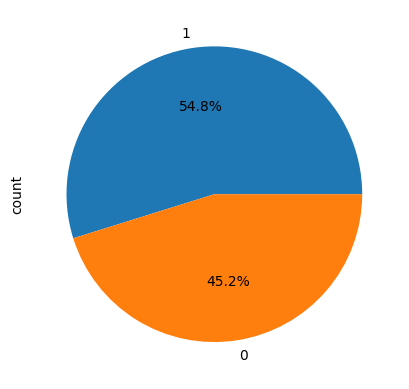

In [21]:
pie = df['type'].value_counts()
pie.plot(kind='pie', autopct='%1.1f%%')
plt.show()

#### Checking no.of records between the true and false news

In [22]:
df['type'].value_counts()

type
1    21192
0    17466
Name: count, dtype: int64

In [23]:
# #if there are missing values we can impute data with knn or mean ,mode ,median
# from sklearn.impute import KNNImputer 
# impute=KNNImputer()

# for i in df.select_dtypes(include="number").columns:
#     df[i]=impute.fit_transform(df[[i]])

# Data Pre-processing

## Tokenization and removal of punctuation and stop words 

### Lowercasing alphabets in dataset in title and text

In [24]:
def preprocess_text(text):
    text = text.lower()
    # Tokenization
    tokens = word_tokenize(text)
    # Remove punctuation
    tokens = [word for word in tokens if word.isalnum()]
    # Remove stop words
    stop_words = set(stopwords.words('english'))
    tokens = [word for word in tokens if word not in stop_words]
    return ' '.join(tokens)


In [25]:
df['text'] = df['text'].apply(preprocess_text)
df

C:\Users\ksanj\AppData\Local\Temp\ipykernel_14500\484235599.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['text'] = df['text'].apply(preprocess_text)


,text,type
0,washington reuters head conservative republica...,1
1,washington reuters transgender people allowed ...,1
2,washington reuters special counsel investigati...,1
3,washington reuters trump campaign adviser geor...,1
4,reuters president donald trump called postal s...,1
...,...,...
44128,21st century wire says world stage men women m...,0
44129,randy johnson 21st century wirethe majority ma...,0
44130,tune alternate current radio network acr anoth...,0
44131,21st century wire says new front opened long b...,0


## Applying stemming and lemmatization

In [26]:
from nltk.stem import PorterStemmer, WordNetLemmatizer
nltk.download('wordnet')
nltk.download('omw-1.4')


[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ksanj\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\ksanj\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [27]:
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

# Function to apply stemming
def apply_stemming(text):
    return stemmer.stem(text)

# Function to apply lemmatization
def apply_lemmatization(text):
    return lemmatizer.lemmatize(text)

In [28]:
df.loc[:, 'text'] = df['text'].apply(apply_stemming)
df.loc[:, 'text'] = df['text'].apply(apply_lemmatization)
df

,text,type
0,washington reuters head conservative republica...,1
1,washington reuters transgender people allowed ...,1
2,washington reuters special counsel investigati...,1
3,washington reuters trump campaign adviser geor...,1
4,reuters president donald trump called postal s...,1
...,...,...
44128,21st century wire says world stage men women m...,0
44129,randy johnson 21st century wirethe majority ma...,0
44130,tune alternate current radio network acr anoth...,0
44131,21st century wire says new front opened long b...,0


## Removal of Special characters and symbols 

In [29]:
df.loc[:, 'text'] = df['text'].str.replace(r'[^\w\s]', '', regex=True)
df

,text,type
0,washington reuters head conservative republica...,1
1,washington reuters transgender people allowed ...,1
2,washington reuters special counsel investigati...,1
3,washington reuters trump campaign adviser geor...,1
4,reuters president donald trump called postal s...,1
...,...,...
44128,21st century wire says world stage men women m...,0
44129,randy johnson 21st century wirethe majority ma...,0
44130,tune alternate current radio network acr anoth...,0
44131,21st century wire says new front opened long b...,0


In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Implementation of CNN 

In [32]:
import pandas as pd
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense

In [33]:
X=df['text']
X

0        washington reuters head conservative republica...
1        washington reuters transgender people allowed ...
2        washington reuters special counsel investigati...
3        washington reuters trump campaign adviser geor...
4        reuters president donald trump called postal s...
                               ...                        
44128    21st century wire says world stage men women m...
44129    randy johnson 21st century wirethe majority ma...
44130    tune alternate current radio network acr anoth...
44131    21st century wire says new front opened long b...
44132    21st century wire says far away guess wants ru...
Name: text, Length: 38658, dtype: object

In [34]:
Y=df["type"]
Y

0        1
1        1
2        1
3        1
4        1
        ..
44128    0
44129    0
44130    0
44131    0
44132    0
Name: type, Length: 38658, dtype: int64

In [35]:


tokenizer = Tokenizer(num_words=10000)  # Limit vocab to 10,000 words
tokenizer.fit_on_texts(df['text'])

# Convert text to sequences of integers
X_sequences = tokenizer.texts_to_sequences(df['text'])

# Pad sequences to ensure they are of the same length
X_padded = pad_sequences(X_sequences, maxlen=1000)  # Adjust maxlen as per your requirement
X_padded

array([[   0,    0,    0, ...,  260,  632,  735],
       [   0,    0,    0, ...,  145, 7223, 1909],
       [   0,    0,    0, ...,   59, 2859,    1],
       ...,
       [   0,    0,    0, ..., 3102,   64,  163],
       [8540,  730, 2103, ..., 4746,  291, 3483],
       [   0,    0,    0, ..., 1376,  432, 5227]])

In [36]:
X_train, X_test, y_train, y_test = train_test_split(X_padded, Y, test_size=0.2, random_state=42)

In [37]:
print(X_padded.shape)
print(Y.shape)

(38658, 1000)
(38658,)


## Defining Model

In [38]:
from tensorflow.keras.layers import Dropout

In [39]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, MaxPooling1D, Flatten, Dense

# Define a simple CNN model
model = Sequential()

# Embedding layer (learns word embeddings)
model.add(Embedding(input_dim=10000, output_dim=50, input_length=200))  # Adjust input_dim, output_dim, input_length

# Convolutional layer
model.add(Conv1D(filters=64, kernel_size=3, activation='relu'))

# Max pooling layer
model.add(MaxPooling1D(pool_size=2))

# Flatten the output for the dense layer
model.add(Flatten())

# Dense layer for classification
model.add(Dense(1, activation='sigmoid'))  # For binary classification

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Summarize the model
model.summary()
model.fit(X_train, y_train, epochs=5, batch_size=32, validation_split=0.2)

C:\Users\ksanj\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d (Conv1D)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
774/774 ━━━━━━━━━━━━━━━━━━━━ 29s 33ms/step - accuracy: 0.8730 - loss: 0.2418 - val_accuracy: 0.9921 - val_loss: 0.0313
Epoch 2/5
774/774 ━━━━━━━━━━━━━━━━━━━━ 26s 33ms/step - accuracy: 0.9992 - loss: 0.0052 - val_accuracy: 0.9924 - val_loss: 0.0287
Epoch 3/5
774/774 ━━━━━━━━━━━━━━━━━━━━ 25s 32ms/step - accuracy: 0.9998 - loss: 0.0018 - val_accuracy: 0.9929 - val_loss: 0.0340
Epoch 4/5
774/774 ━━━━━━━━━━━━━━━━━━━━ 27s 34ms/step - accuracy: 1.0000 - loss: 4.9472e-04 - val_accuracy: 0.9934 - val_loss: 0.0323
Epoch 5/5
774/774 ━━━━━━━━━━━━━━━━━━━━ 26s 33ms/step - accuracy: 1.0000 - loss: 8.7363e-05 - val_accuracy: 0.9932 - val_loss: 0.0360


In [40]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [41]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np

# Assuming you have already trained the CNN model and have the data ready

# 1. Calculate training accuracy using model.evaluate()
train_loss, train_accuracy = model.evaluate(X_train,y_train, batch_size=32)
print(f"Training Accuracy: {train_accuracy:.4f}")

# 2. Make predictions on the test data
y_pred = model.predict(X_test)

# Since the CNN model typically outputs probabilities (for binary classification), 
# we need to convert these to class labels (0 or 1 for binary classification)
y_pred_class = (y_pred > 0.5).astype(int)  # If you have binary classification

# If you have multi-class classification, use argmax to get the predicted class:
# y_pred_class = np.argmax(y_pred, axis=1)

# 3. Calculate test accuracy using accuracy_score
test_accuracy = accuracy_score(y_test, y_pred_class)
print(f"Test Accuracy: {test_accuracy:.4f}")

# 4. Print the classification report (precision, recall, F1-score)
print("Classification Report:")
print(classification_report(y_test, y_pred_class))

# 5. Print the confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_class))


967/967 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.9997 - loss: 0.0014
Training Accuracy: 0.9986
242/242 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step
Test Accuracy: 0.9928
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3528
           1       0.99      0.99      0.99      4204

    accuracy                           0.99      7732
   macro avg       0.99      0.99      0.99      7732
weighted avg       0.99      0.99      0.99      7732

Confusion Matrix:
[[3501   27]
 [  29 4175]]


## Hyperparameter tuning by keras tuner 

In [ ]:
import keras_tuner as kt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense
from tensorflow.keras.optimizers import Adam

# Define a function to build the model with hyperparameters
def build_model(hp):
    model = Sequential()
    
    # Embedding layer with tunable hyperparameters
    model.add(Embedding(input_dim=max_words, 
                        output_dim=hp.Int('embedding_output_dim', min_value=64, max_value=256, step=64), 
                        input_length=max_len))
    
    # Convolutional layer with tunable hyperparameters
    model.add(Conv1D(filters=hp.Int('filters', min_value=32, max_value=256, step=32),
                     kernel_size=hp.Int('kernel_size', min_value=3, max_value=7, step=1),
                     activation=hp.Choice('activation', values=['relu', 'tanh', 'sigmoid'])))
    
    # Pooling layer with tunable hyperparameters
    model.add(GlobalMaxPooling1D())
    
    # Dense layer with tunable hyperparameters
    model.add(Dense(hp.Int('dense_units', min_value=32, max_value=128, step=32), 
                    activation=hp.Choice('activation', values=['relu', 'tanh'])))
    
    # Output layer
    model.add(Dense(1, activation='sigmoid'))
    
    # Compile the model with tunable learning rate
    model.compile(optimizer=Adam(learning_rate=hp.Float('learning_rate', min_value=1e-5, max_value=1e-2, sampling='LOG')), 
                  loss=hp.Choice('loss', values=['binary_crossentropy', 'hinge']),
                  metrics=['accuracy'])
    
    return model

# Define the hyperparameter tuner
tuner = kt.RandomSearch(build_model,
                        objective='val_accuracy',
                        max_trials=5,
                        executions_per_trial=1,
                        directory='hyperparam_tuning',
                        project_name='text_classification')

# Run hyperparameter tuning
tuner.search(X_train_pad, y_train, epochs=5, batch_size=32, validation_split=0.2)

# Get the best model
best_model = tuner.get_best_models(num_models=1)[0]

# Evaluate the best model
best_model.evaluate(X_train, y_test)


242/242 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step


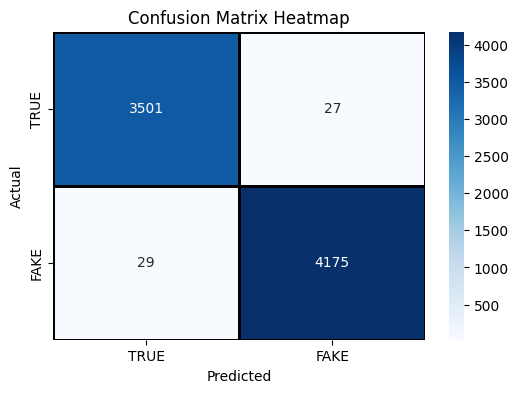

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Make predictions on the test data
pred = model.predict(X_test)

# Convert probabilities to binary predictions (0 or 1)
# Assumes that the model outputs probabilities, so a threshold of 0.5 is used for classification
pred = (pred >= 0.5).astype(int)

# Calculate confusion matrix
cm = confusion_matrix(y_test, pred)

# Convert confusion matrix to DataFrame for easier visualization
cm_df = pd.DataFrame(cm, index=['True', 'Fake'], columns=['True', 'Fake'])

# Plotting the confusion matrix as a heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(cm_df, cmap="Blues", annot=True, fmt='d', linewidth=1, linecolor='black', 
            xticklabels=['TRUE', 'FAKE'], yticklabels=['TRUE', 'FAKE'], cbar=True)

# Add title and axis labels
plt.title('Confusion Matrix Heatmap')
plt.ylabel('Actual')
plt.xlabel('Predicted')

# Display the heatmap
plt.show()




In [44]:
model.save('cnn_model.keras')  # Saves the model in the new .keras format


In [45]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Example unseen data (replace this with your actual unseen data)
unseen_data = testSent =["Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing",
           "A Fargo, North Dakota, man was arrested for clearing snow with a flamethrower.",
    "Trey Gowdy destroys this clueless DHS employee when asking about the due process of getting on the terror watch list. Her response is priceless:  I m sorry, um, there s not a process afforded the citizen prior to getting on the list.  ",
       "Poland s new prime minister faces a difficult balancing act trying to repair bruised relations with the European Union without alienating the eurosceptic government s core voters. A Western-educated former banker who is fluent in German and English and was sworn in on Monday, Mateusz Morawiecki boasts the credentials needed to negotiate with Brussels. But any compromises to improve relations with Brussels, which sees the ruling Law and Justice (PiS) party as a threat to democracy, would risk upsetting the traditional, Catholic supporters who propelled it into power two years ago. It is a gamble that could backfire, and it is not yet clear how far Morawiecki, 49, and his party, dominated by former Prime Minister Jaroslaw Kaczynski, are ready to go to please Brussels.   The idea to build up international credibility seems rational,  said Jaroslaw Flis, a sociologist at the Jagiellonian University.  But such actions would have to be in complete contrast with what Mateusz Morawiecki would have to do domestically to prevent the PiS from falling apart.  The PiS government has alienated many people at home and abroad with its nationalist rhetoric and changes to state institutions which the EU says subvert the bloc s laws. The European Commission, the EU executive, opened an inquiry into the rule of law in Poland in January 2016 and the European Parliament has started a process that could deprive Poland of its voting rights in the 28-nation bloc. Any hope in Brussels that Morawiecki s appointment signals a change of course by PiS will have been tempered by Polish parliament approving legal changes to the judiciary in defiance of the EU on Friday - the day after his nomination. The changes give parliament, where PiS has a majority, de facto control over the selection of judges. EU leaders looking for clues about Morawiecki s plans will also have taken little comfort from comments he has made since being nominated, making clear he backs a tough line on the EU and believes in PiS s traditional vision of the Polish state.   We want to transform Europe, this is my dream, to re-christianise it,  Morawiecki told the Catholic Radio Maryja broadcaster.  We want Poland to be strong, but also to contain ... Christian values. We will defend them against the background of laicisation and a deepening consumerism.  Asked by the radio interviewer about demands by French President Emmanuel Macron for Poland to face sanctions over a subversion of democratic rules, Morawiecki said he would not  bow down to blackmail.  In comments to parliament on Tuesday, Morawiecki suggested Poland might relent in a conflict with Brussels over logging in an ancient forest, which an EU court has said contravenes EU laws. But he said Poland s national interests came first in any debate over the future of the EU and that he  wholeheartedly  supported PiS s overhaul of the judiciary. Like Beata Szydlo, whom he replaced as prime minister, Morawiecki is likely to have to defer to PiS leader and co-founder Jaroslaw Kaczynski. Prime minister from July 2006 to November 2007, Kaczynski is widely seen as the power behind the party and Poland s main decision-maker. How much scope that will leave Morawiecki to carve out his own path remains to be seen. Former Polish President Lech Walesa, a PiS critic, has suggested that nothing of substance will change.  The circus has stayed the same, only the clowns have changed their roles,  Walesa, who led the Solidarity trade union movement that ended communist rule, said on Twitter.  The appointment of Morawiecki, whose father founded and led a radical offshoot of Solidarity in the 1980s, appears designed in part to present a new face of Poland to the EU. Szydlo, 54, at times responded angrily to EU criticism and relations with the bloc soured under her government. Underlining PiS opposition to Muslim immigration, she said last month Poland wanted to be sure Christian traditions were not subject to  ideological censorship  in the EU. Along with Hungary, Poland has refused to take in any of its quota of the wave of refugees from Syria and elsewhere who have come to Europe since 2015, on the grounds that Muslim immigrants are a threat to national security and stability.         Such comments appeal to core PiS voters, and Szydlo s government, which promised generous welfare payouts and a dedication to traditional Catholic values, was one of Poland s most popular since communist rule ended in 1989. A relative newcomer to politics, Morawiecki lacks Szydlo s broad appeal. But he has overseen significant economic achievements since becoming finance minister in 2016, a position he has retained in the new government. Tusk has welcomed what he sees as signs that Morawiecki is a liberal economist who wants better ties with the EU.  There is no doubt that (Morawiecki s) liberal bias and some pro-western gestures could be a sign that there is a lurking desire to improve relations,  Tusk said last week. But an economic stimulus plan Morawiecki unveiled in 2016 has been criticized by economists who say it depends heavily on private investment, which is low in Poland despite fast economic growth.  What Morawiecki sees as a solution, meaning more political influence in the economy, is actually dangerous,  said Leszek Balcerowicz, a former finance minister who coordinated the transition to a market economy after decades of communist rule. Any hint of protectionism is also likely to worry EU leaders, who seek to break down trade barriers.  Morawiecki has called the privatization of state-owned companies a tragedy and said he will give more power to domestic capital at the expense of foreign investors. In his comments to parliament on Tuesday, he said economic policy should not change.  ",
      ]
df_data=pd.DataFrame(unseen_data,columns=["unseen_data"])

df_data['text'] = df_data['unseen_data'].apply(preprocess_text)
df_data.loc[:, 'text'] = df_data['text'].apply(apply_stemming)
df_data.loc[:, 'text'] = df_data['text'].apply(apply_lemmatization)
df_data.loc[:, 'text'] = df_data['text'].str.replace(r'[^\w\s]', '', regex=True)

# Initialize the Tokenizer and fit on the text data
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(df_data['text'])

# Convert the text column to sequences
df_data['text'] = df_data['text'].apply(lambda x: tokenizer.texts_to_sequences([x])[0])

# Pad the sequences
max_len = 1000  # Define your max length
df_data['text'] = list(pad_sequences(df_data['text'], maxlen=max_len))
df_data.shape

import numpy as np

padded_sequences = np.array(df_data['text'].tolist())
padded_sequences.shape

predictions = model.predict(padded_sequences)
print(predictions)

predicted_classes = (predictions > 0.5).astype("int32") 

df_data['predictions'] = predicted_classes
df_data['predictions'] = df_data['predictions'].map({1: 'True', 0: 'False'})

# Optionally, print or inspect the predictions
print(df_data[['unseen_data', 'predictions']])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
[[3.2705074e-04]
 [5.7908363e-07]
 [1.8759597e-02]
 [1.0000000e+00]]
                                         unseen_data predictions
0  Donald Trump Sends Out Embarrassing New Year’s...       False
1  A Fargo, North Dakota, man was arrested for cl...       False
2  Trey Gowdy destroys this clueless DHS employee...       False
3  Poland s new prime minister faces a difficult ...        True
